参数更正：实际羽化限位为 ±26.1°。本记录的仿真结果采用历史 ±50°，仅作历史对照；当前结果见 experiments/fixbase/IST_robot_single_wing_26p1deg.ipynb。

# 单翼实测与仿真差异分析



差异由两部分组成：实测文件的运行/停机区间及非零基线放大了表面差距；原气动模型使用了矩形翼面积和统一作用点，导致真实曲线翼的气动几何不匹配。
用户已确认编码器记录减速输出轴，每转一圈对应一次扑翼周期；实物与 CAD 同尺寸，扑翼幅度和羽化限位相同。
当前统计仍有一个明确前提：**把力记录末段低振动区视为同装配状态的停机基线，且 Fz 正向与升力同向**。力传感器清零方式、两种力文件的生成方式尚未得到确认，以下实测升力据此解释。

原仿真在 10 Hz 给出 21.51 mN，实测基线校正后约 15.22 mN；15 Hz 分别为 47.57 与 29.85 mN。
所以不能继续把原仿真数值当作已经验证的升力预测。此前采用最大翼弦作为整翼弦长，是模型实现中的几何简化问题。



通过：72 个输入文件哈希一致，18 组基线统计重新计算一致。


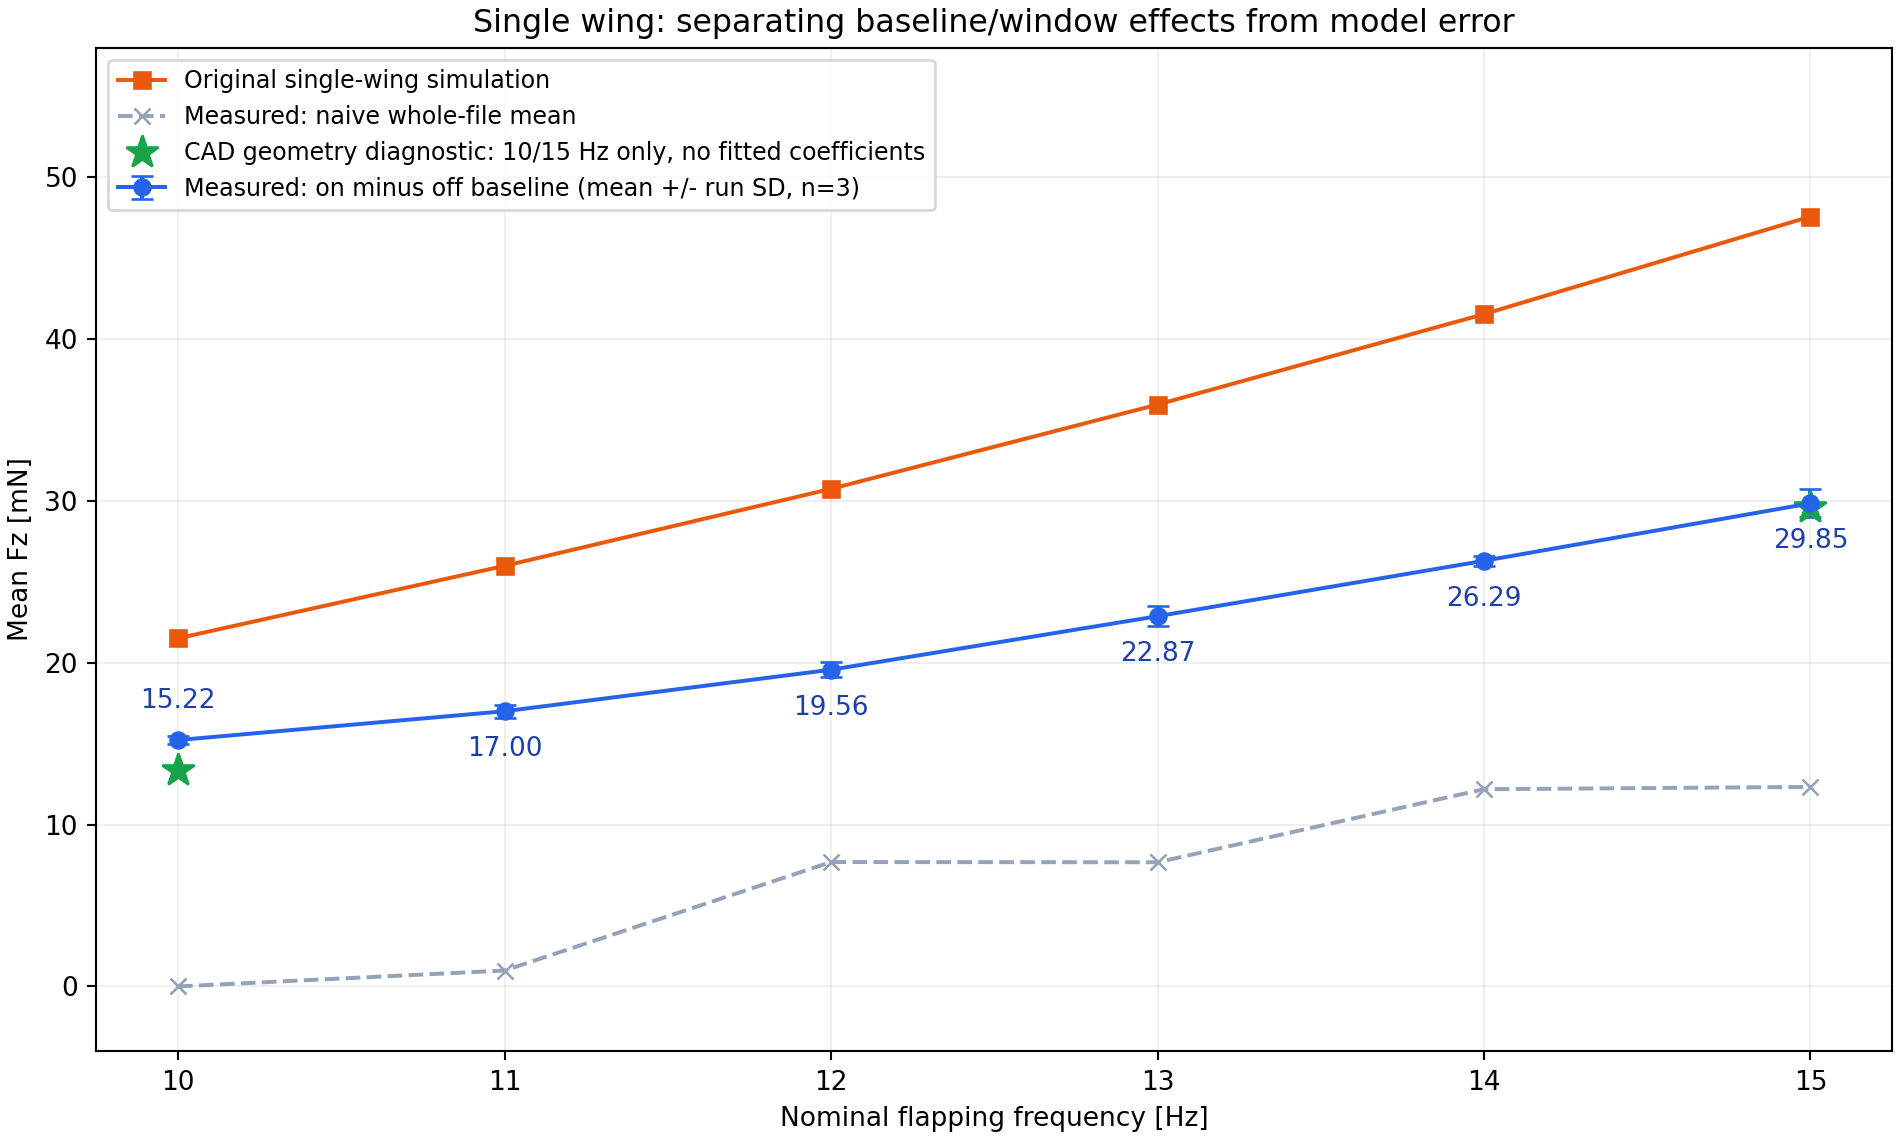

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
from IPython.display import display, Image, Markdown
FOLDER=Path.cwd().resolve()
sys.path.insert(0,str(FOLDER))
from analyze_comparison import load_force,window_mean
OUTPUT=FOLDER/'analysis'
analysis=json.loads((OUTPUT/'analysis.json').read_text())
for s in analysis['sources']:
    assert hashlib.sha256((FOLDER/s['file']).read_bytes()).hexdigest()==s['sha256']
for row in analysis['summary']:
    paths=sorted((FOLDER/'0831_curve_capton').rglob(f"*_{row['target_hz']}Hz_*.csv.csv"))
    corrected=[]
    for path in paths:
        a=load_force(path)
        corrected.append(1000*(window_mean(a,.5,4)-window_mean(a,5.5,a[-1,0]-.1)))
    assert len(corrected)==3
    assert np.isclose(np.mean(corrected),row['real_mean_Fz_mN'])
print('通过：72 个输入文件哈希一致，18 组基线统计重新计算一致。')
display(Image(filename=str(OUTPUT/'comparison.png')))

| 频率 Hz | 实测基线校正 Fz / mN（均值 ± 记录间 SD） | 原仿真 / mN | 仿真偏高 | 编码器实测 Hz |
|---:|---:|---:|---:|---:|
| 10 | 15.22 ± 0.22 | 21.51 | 41.3% | 10.122 |
| 11 | 17.00 ± 0.39 | 25.98 | 52.8% | 11.137 |
| 12 | 19.56 ± 0.48 | 30.74 | 57.1% | 12.059 |
| 13 | 22.87 ± 0.63 | 35.95 | 57.2% | 13.034 |
| 14 | 26.29 ± 0.30 | 41.54 | 58.0% | 14.005 |
| 15 | 29.85 ± 0.87 | 47.57 | 59.4% | 14.951 |

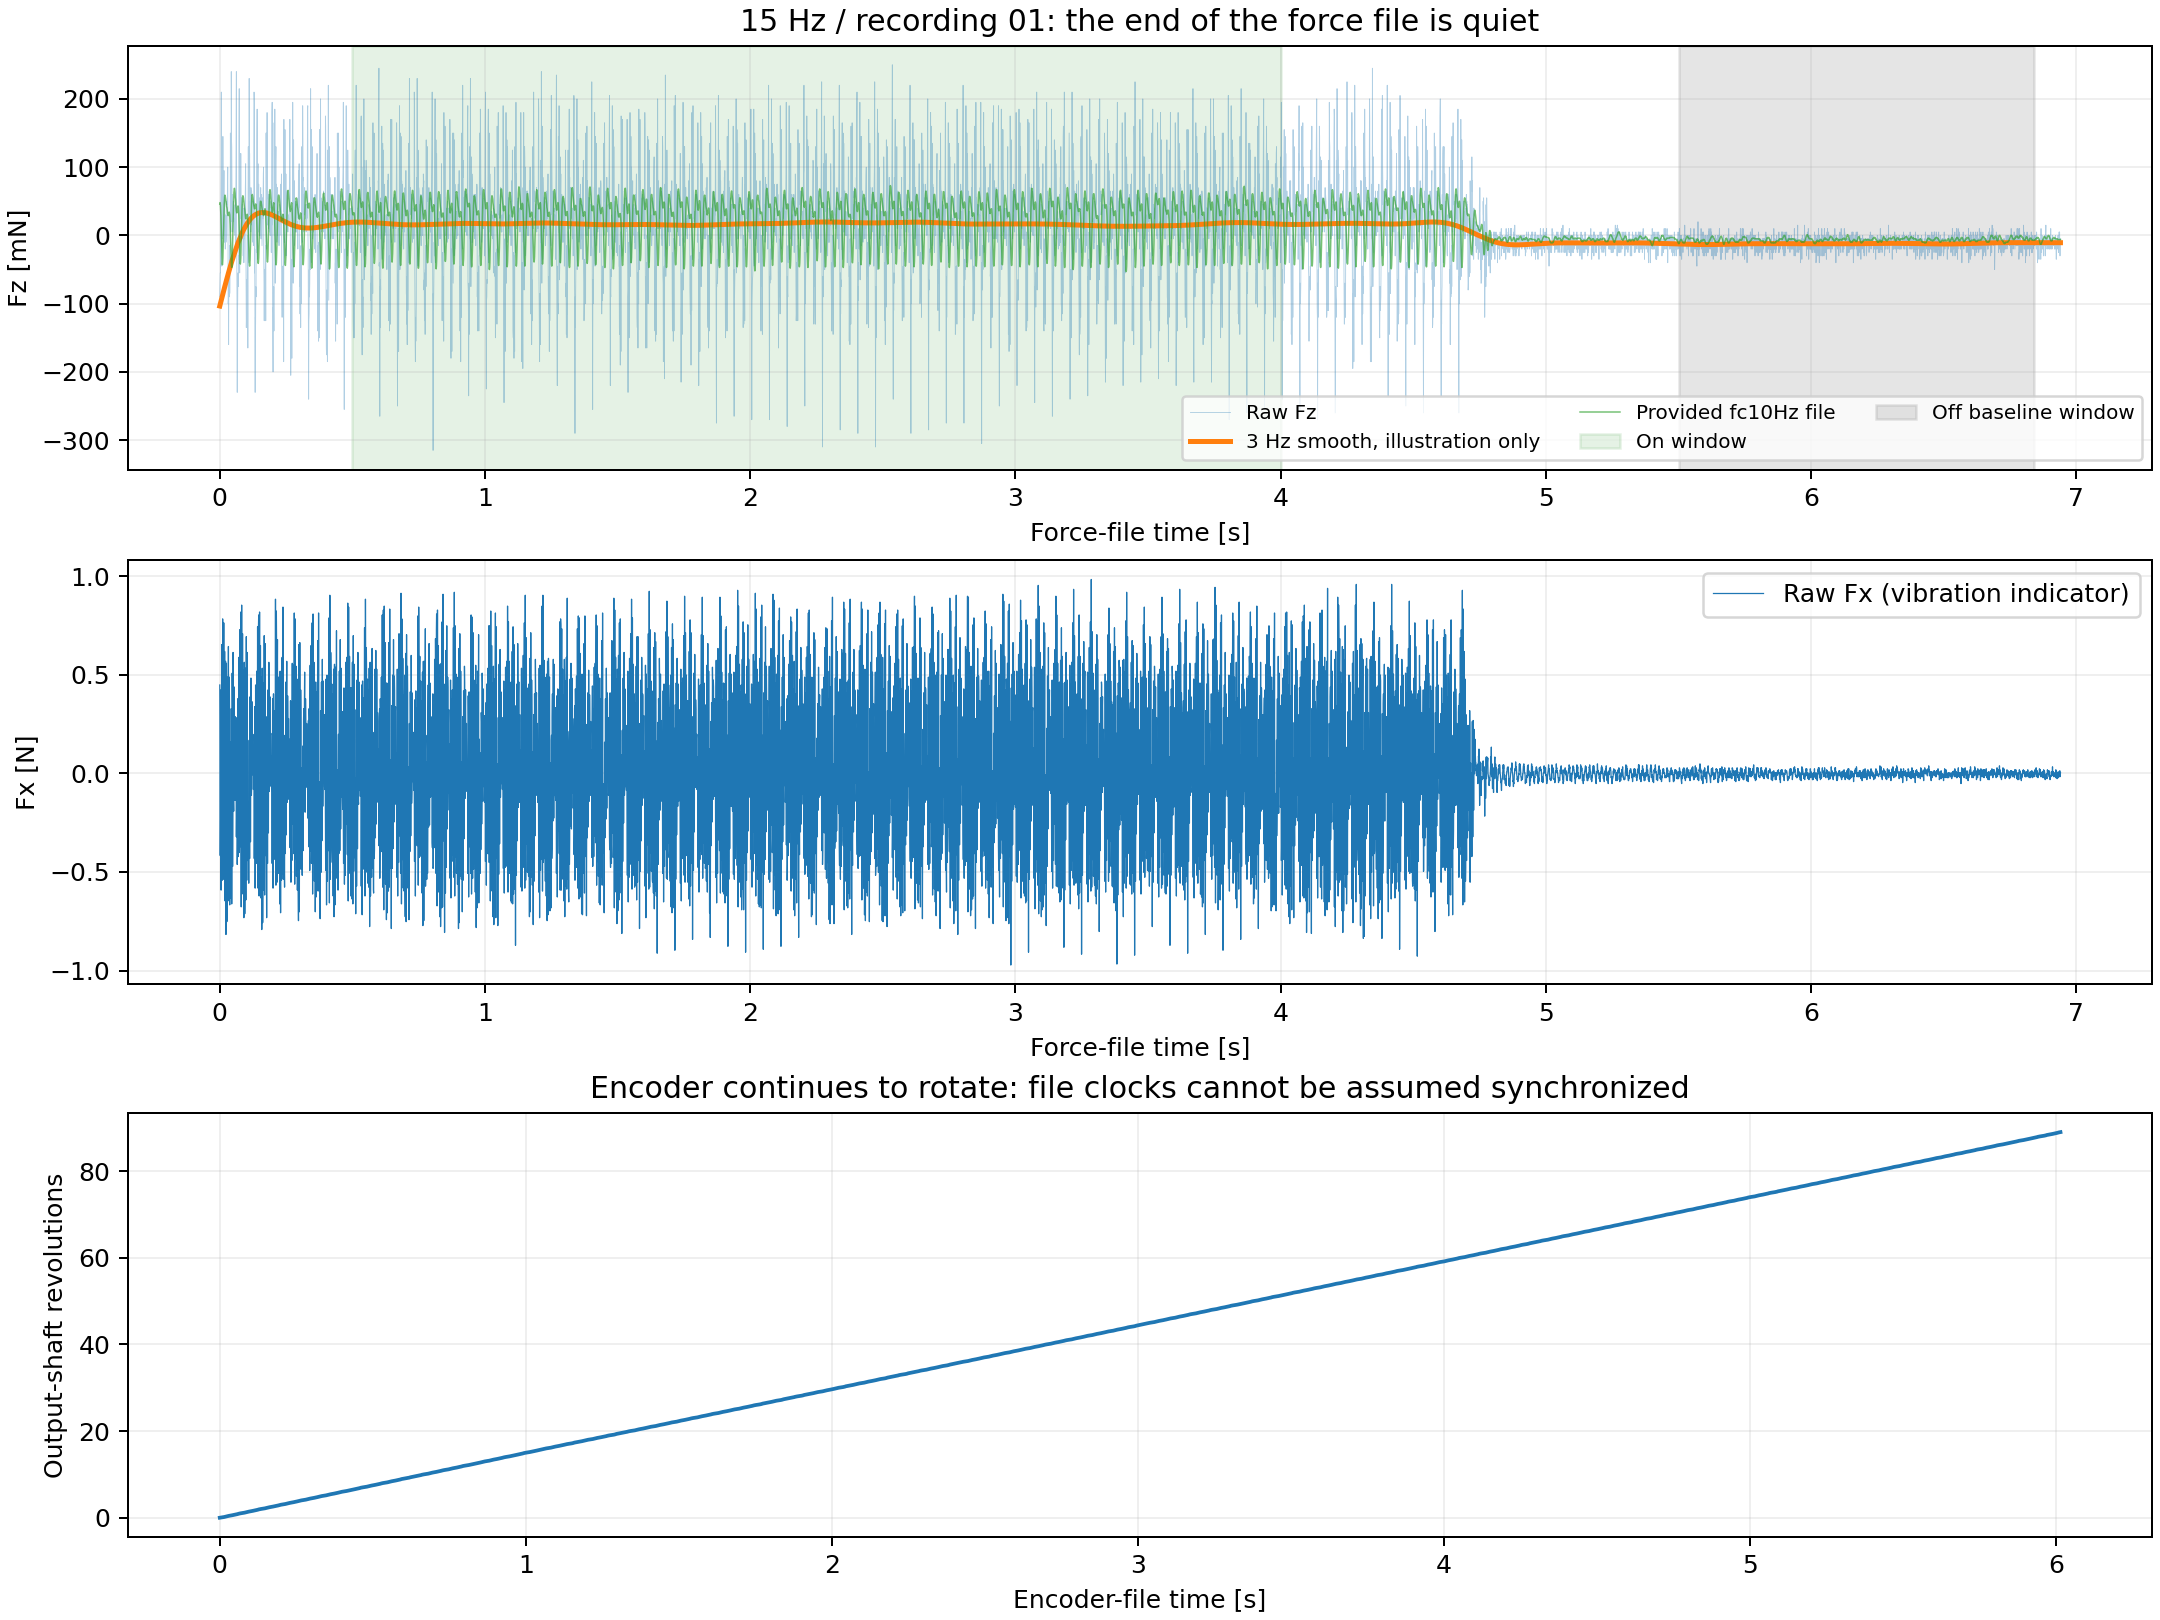

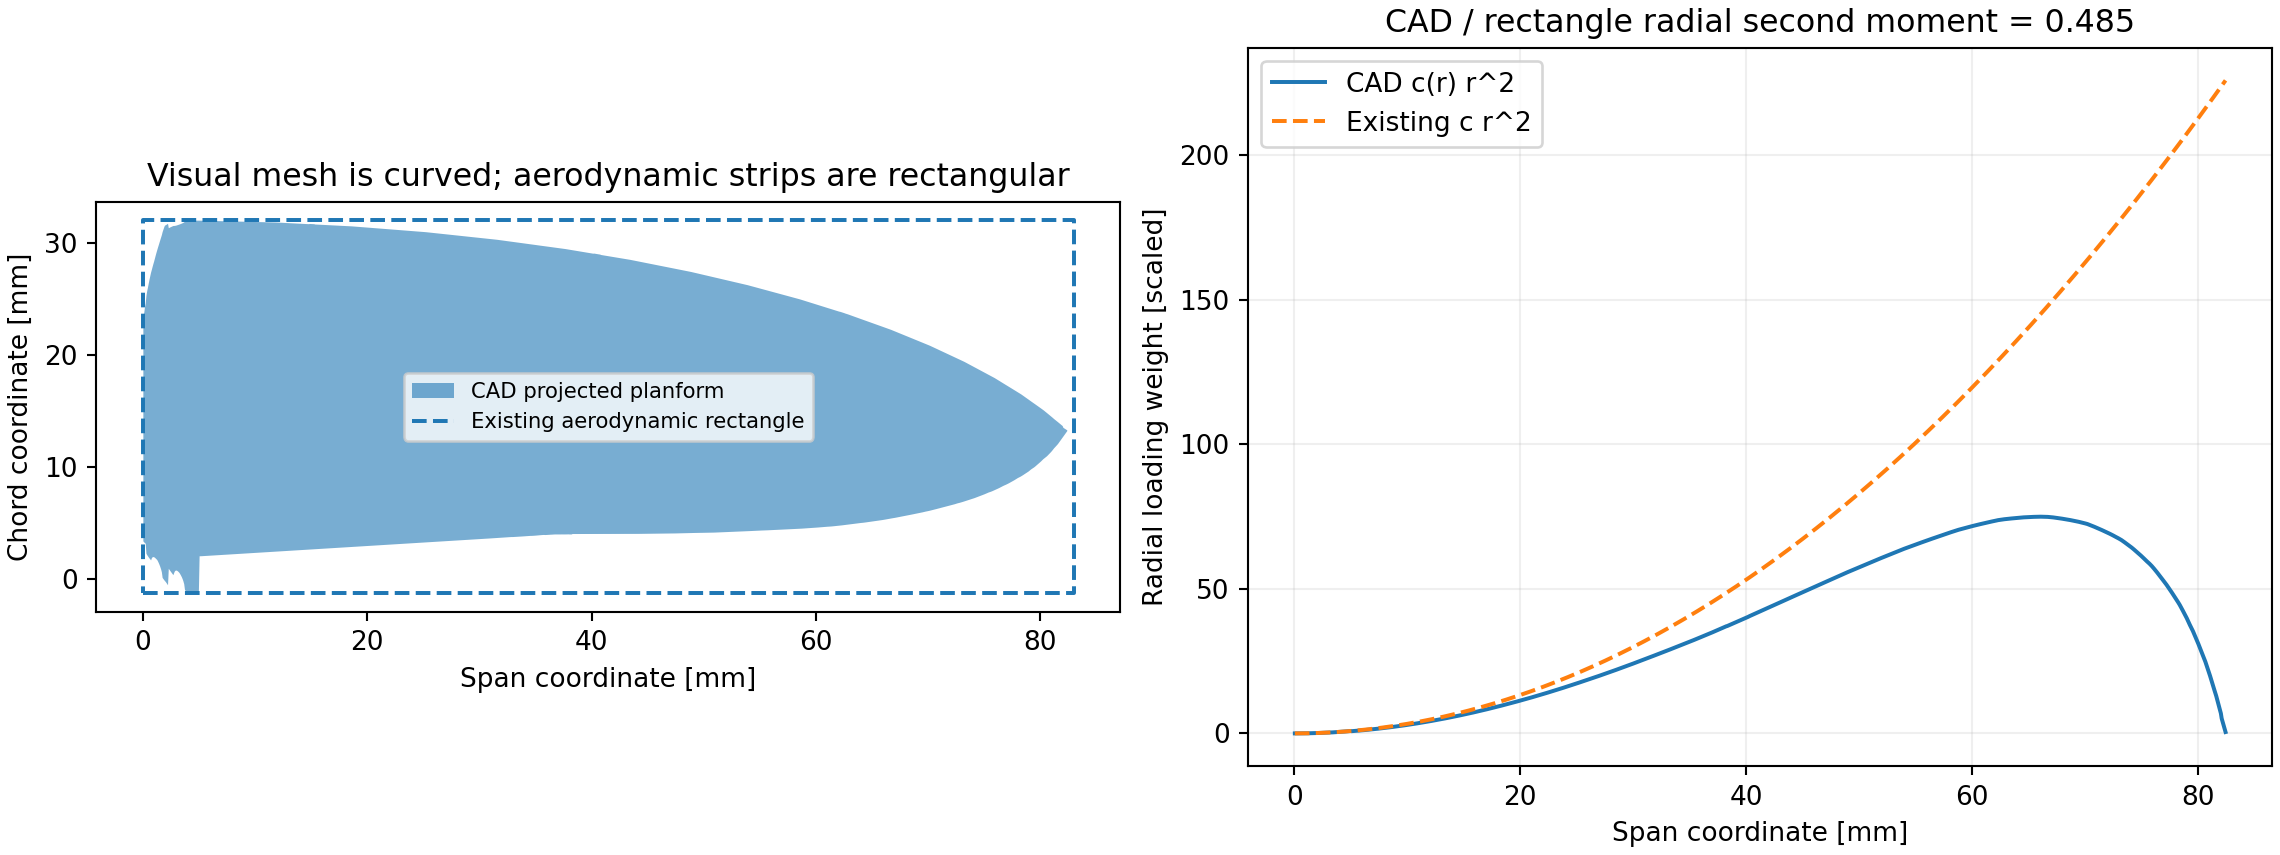

In [2]:
display(Image(filename=str(OUTPUT/'window_and_baseline.png')))
display(Image(filename=str(OUTPUT/'planform_mismatch.png')))

## 几何控制变量诊断

| Hz | 原矩形模型 | 仅替换条带面积 | CAD 面积、作用点和旋转阻尼 | 实测基线校正 |
|---:|---:|---:|---:|---:|
| 10 | 21.51 | 10.14 | 13.34 | 15.22 |
| 15 | 47.57 | 22.39 | 29.60 | 29.85 |

全部值来自独立仿真，没有用实测力拟合系数。

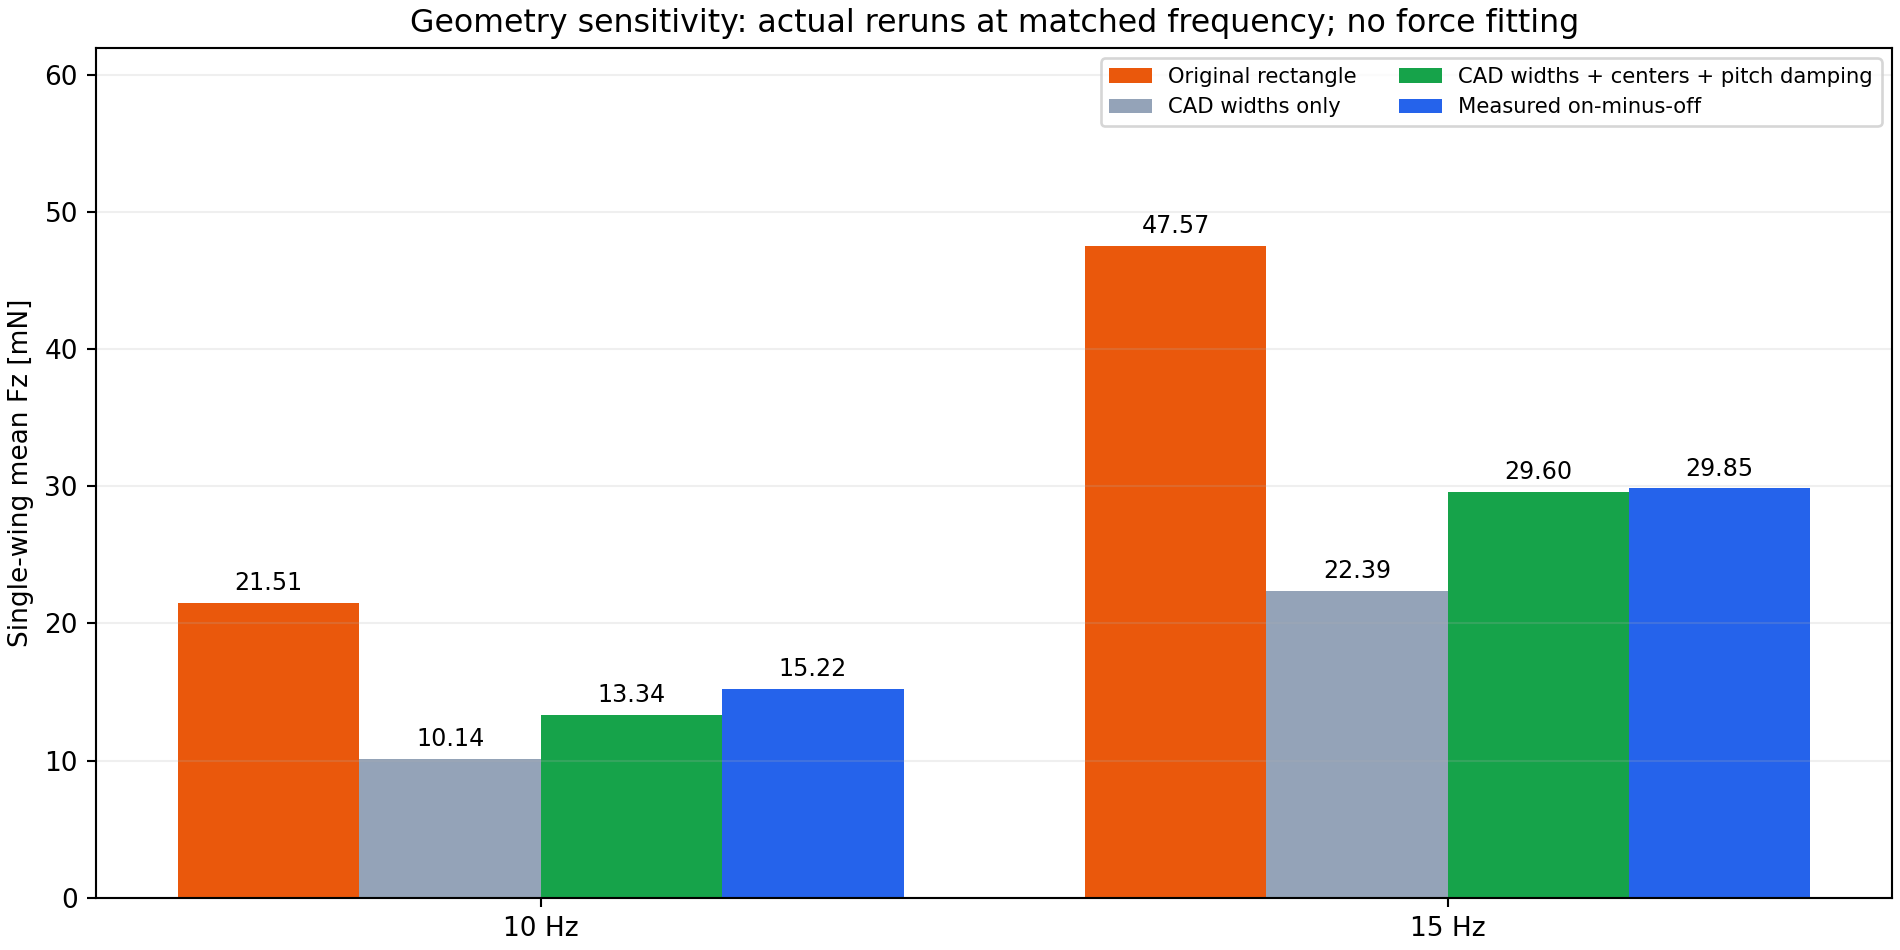

In [3]:
display(Image(filename=str(OUTPUT/'geometry_sensitivity.png')))

详细假设、因果边界、源文件和复现命令见 `analysis/analysis_report.md`。